# 01 · Exploratory Data Analysis

**Question:** what does the activity log look like, how clean is it, and which behaviours separate students who pass from those who fail?

The raw file is a *wide activity log*: one row per student × course × day (`particion`) × activity. This notebook works mostly on the normalized tables produced by `early-warning clean` (see `src/early_warning/data/clean.py`), and goes back to the raw file only to show its structure.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from early_warning.config import load_config
from early_warning.data.clean import load_tables
from early_warning.data.load import load_raw
from early_warning.viz import FAIL, NEUTRAL, PASS, save, set_style

set_style()
pd.set_option("display.max_columns", 40)
cfg = load_config()
raw = load_raw(cfg.path("raw_csv"))
t = load_tables(cfg.path("interim_dir"))
enr = t.enrollments
print(f"raw: {raw.shape[0]:,} rows x {raw.shape[1]} columns")
{k: len(v) for k, v in t.as_dict().items()}

raw: 196,124 rows x 24 columns


{'enrollments': 2969,
 'exams': 5842,
 'assignments': 4239,
 'assignment_events': 22940,
 'submissions': 21938}

## 1. Structure of the raw log

Every enrollment (student × course) has **exactly 60 partitions**, and most rows are empty placeholders: an activity column is filled in only on days when something happened. Exam, assignment and submission columns are filled independently, so a row can mix an assignment with an unrelated submission.

In [2]:
activity = pd.DataFrame(
    {
        "exam": raw["nombre_examen"].notna(),
        "assignment": raw["assignment_id"].notna(),
        "submission": raw["sub_uuid"].notna(),
    }
)
activity["none"] = ~activity.any(axis=1)
summary = activity.mean().mul(100).round(1).rename("% of rows").to_frame()
summary["rows"] = activity.sum()
mismatch = (
    raw["assignment_id"].notna()
    & raw["sub_uuid"].notna()
    & (raw["ass_name"] != raw["ass_name_sub"])
).sum()
print(f"rows holding an assignment AND a submission for a *different* task: {mismatch:,}")
summary

rows holding an assignment AND a submission for a *different* task: 4,129


,% of rows,rows
exam,3.6,7010
assignment,13.3,26061
submission,12.3,24206
none,75.9,148860


In [3]:
per_enr = raw.groupby(["user_uuid", "course_uuid"])["particion"].agg(["nunique", "min", "max"])
per_enr.describe().loc[["min", "max", "mean"]]

,nunique,min,max
min,60.0,0.0,59.0
max,60.0,0.0,59.0
mean,60.0,0.0,59.0


## 2. Data-quality issues and decisions

The challenge explicitly asks to find the inconsistencies and justify the decisions. They are detected and handled in code; the report below is generated by the cleaning step itself.

In [4]:
from IPython.display import Markdown

Markdown((cfg.path("metrics_dir") / "data_quality_report.md").read_text())

| Check | Affected | Decision |
|---|---:|---|
| Exact duplicate rows | 1,730 | Dropped. They carry no extra information (mostly empty day-placeholder rows). |
| `periodo` written as '01-2022' instead of '1-2022' | 7,730 | Normalized to the dictionary format 'S-YYYY'. Raw label kept in `periodo_raw`. Note: these enrollments ran Jan-Mar 2022, earlier than the bulk of 1-2022. |
| `particion` ranges 0..59, dictionary says 1..60 | 194,394 | Kept as a 0-based day index (every enrollment has exactly 60 partitions). `day = particion + 1` is used in reports. |
| Students (`user_uuid`) with more than one `legajo` | 1 | `user_uuid` is the identity key; `legajo` is an administrative attribute and is not used for joins or modeling. |
| `course_name` shared by several `course_uuid` | 17 | `course_uuid` is the course key; names are display-only. |
| Enrollments with more than one final grade | 0 | None expected; if present, the last partition's grade is kept (dictionary: 'última nota del examen final'). |
| Final grade = 0 | 5 | Treated as 'absent at the final exam' (these students have partial-exam averages of 5-9.5). Excluded from modeling (ambiguous label). |
| Exam rows repeated across activity rows of the same day | 1,168 | De-duplicated to one row per student-course-exam (grade and day were identical). |
| Assignments with `points_possible` = 0 but graded submissions | 3 | Configuration error in the LMS. Scores are on a 0-100 scale everywhere, so `score` is used directly as a percentage instead of `score / points_possible`. |
| Assignments whose lock date differs from due date | 5 | Lock = due for almost all assignments, so 'late submission' is not a usable signal; submission margin (hours before due) is used instead. |
| Submission rows repeated (same `sub_uuid`) | 2,055 | De-duplicated by `sub_uuid` (all attributes were identical). |
| Submission `s_created_at` later than `s_submitted_at` | 21,929 | ~all share 2022-08-01 (a bulk load/migration timestamp). Column dropped. |
| Submissions graded before being submitted | 5 | Grading timestamp set to missing (impossible order). |
| Submissions without score (not graded) | 326 | Kept: they count as submissions; excluded from score statistics. |
| Scores outside 0..100 | 0 | Clipped to 0..100. |
| Assignment names duplicated within a course | 11 | When linking submissions to assignments by name, the one with the latest due date is used. |
| Submissions that could not be linked to an assignment | 2,430 | Kept; their timing features are missing (handled by the models). |


Two findings worth highlighting:

* **`01-2022` is not only a typo.** Its submissions are dated Jan–Mar 2022, earlier than the bulk of `1-2022`. The label is normalized (the dictionary only allows `S-YYYY`), but the raw value is kept for audit.
* **Row-level checks can mislead.** A naive `score > points_possible` check flags 32 rows, but those rows pair a submission with an *unrelated* assignment. After linking submissions to assignments by name, only 3 assignments have `points_possible = 0` (an LMS configuration error), and every score is in 0–100.

In [5]:
for label, sub in t.submissions.merge(enr[["user_uuid", "course_uuid", "periodo_raw"]]).groupby(
    "periodo_raw"
):
    d = sub["submitted_at"]
    print(f"{label:8s} submissions {len(sub):6,}  from {d.min():%Y-%m-%d} to {d.max():%Y-%m-%d}")

01-2022  submissions    779  from 2022-01-28 to 2022-03-02
1-2022   submissions 21,142  from 2022-02-19 to 2022-07-19
2-2022   submissions     17  from 2022-09-06 to 2022-10-03


## 3. Target

enrollments used for modeling: 2,964  |  failure rate: 5.3%  (156 failures)


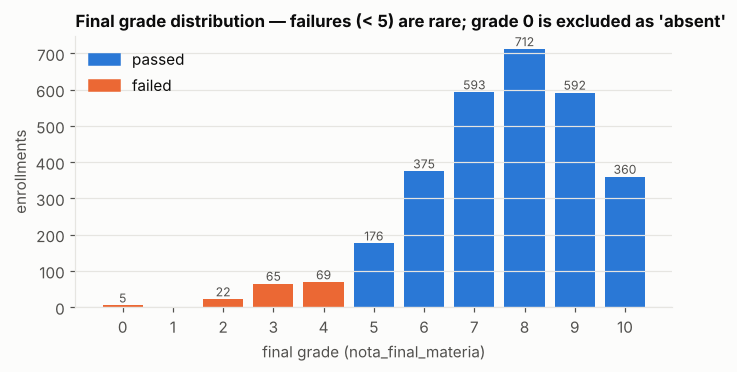

In [6]:
model_enr = enr[~enr["excluded"]]
rate = 1 - model_enr["passed"].mean()
print(
    f"enrollments used for modeling: {len(model_enr):,}  |  failure rate: {rate:.1%}  ({(1 - model_enr['passed']).sum()} failures)"
)

fig, ax = plt.subplots(figsize=(7, 3.2))
counts = enr["final_grade"].value_counts().sort_index()
colors = [FAIL if g < cfg.data["pass_threshold"] else PASS for g in counts.index]
ax.bar(counts.index, counts.values, color=colors, width=0.8)
ax.set_xticks(range(0, 11))
ax.set_xlabel("final grade (nota_final_materia)")
ax.set_ylabel("enrollments")
ax.set_title("Final grade distribution — failures (< 5) are rare; grade 0 is excluded as 'absent'")
for g, v in counts.items():
    ax.annotate(f"{v}", (g, v), ha="center", va="bottom", fontsize=8, color="#52514e")
from matplotlib.patches import Patch

ax.legend(
    handles=[Patch(color=PASS, label="passed"), Patch(color=FAIL, label="failed")], loc="upper left"
)
save(fig, "01_target_distribution")

Implications for modeling: **~5% positives** means accuracy is meaningless (a constant "pass" scores 95%). Model comparison uses **PR-AUC** (baseline = prevalence) and the deployed classifier is tuned to an explicit recall target. The grade is also modeled as a regression target, which uses the full 0–10 signal instead of a single bit.

## 4. Who are the students and courses?

students: 600, median courses each: 5
courses: 582, 41% have a single student in the data


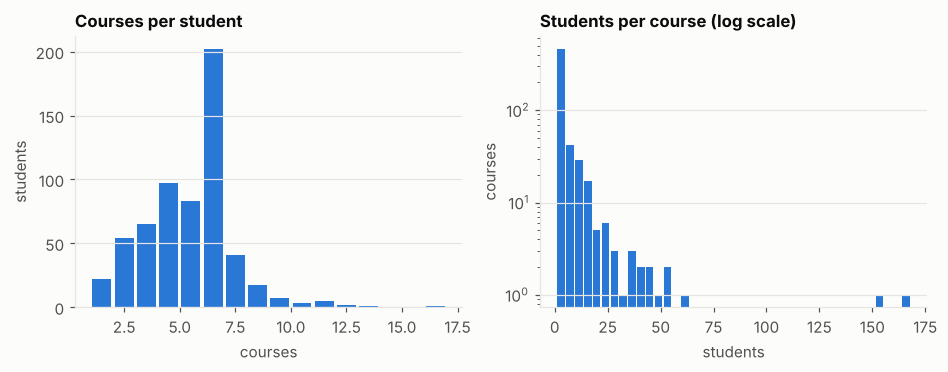

In [7]:
per_user = model_enr.groupby("user_uuid").size()
per_course = model_enr.groupby("course_uuid").size()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(per_user, bins=range(1, per_user.max() + 2), color=PASS, rwidth=0.85)
axes[0].set_title("Courses per student")
axes[0].set_xlabel("courses")
axes[0].set_ylabel("students")
axes[1].hist(per_course, bins=40, color=PASS, rwidth=0.85)
axes[1].set_yscale("log")
axes[1].set_title("Students per course (log scale)")
axes[1].set_xlabel("students")
axes[1].set_ylabel("courses")
save(fig, "01_students_courses")
print(f"students: {per_user.size}, median courses each: {per_user.median():.0f}")
print(
    f"courses: {per_course.size}, {(per_course == 1).mean():.0%} have a single student in the data"
)

Students take ~5 courses each, so **their rows are not independent**: a student who struggles in one course tends to struggle in others. All validation in this project is therefore **grouped by student** (no student appears in both train and test). Course sizes are very skewed (many single-student courses), which rules out course-level target encoding.

## 5. Exams: timing and grades

,count,mean,std,min,25%,50%,75%,max
exam_code,,,,,,,,
P1,2634.0,7.20,1.81,0.0,6.0,7.0,9.00,10.0
P2,2664.0,7.31,1.85,0.0,6.0,7.0,9.00,10.0
R1,167.0,7.40,1.66,3.0,6.0,8.0,8.00,10.0
R2,94.0,7.22,1.51,5.0,6.0,7.0,8.75,10.0
INT,274.0,5.78,1.64,0.0,5.0,6.0,7.00,10.0


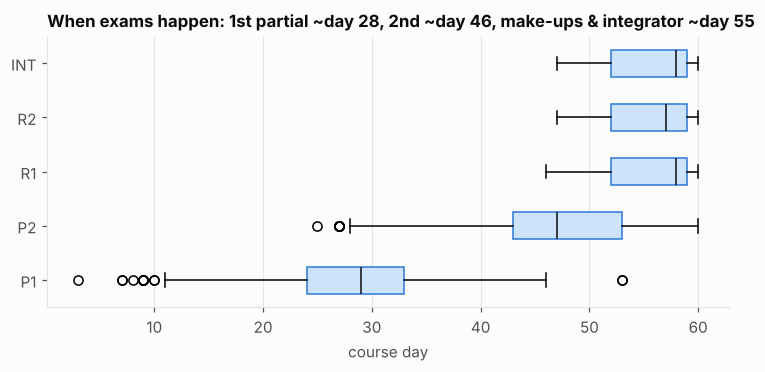

In [8]:
ex = t.exams.merge(model_enr[["user_uuid", "course_uuid", "final_grade", "passed"]])
order = ["P1", "P2", "R1", "R2", "INT"]
fig, ax = plt.subplots(figsize=(8, 3.2))
data = [ex.loc[ex["exam_code"] == c, "particion"] + 1 for c in order]
bp = ax.boxplot(
    data,
    orientation="horizontal",
    tick_labels=order,
    patch_artist=True,
    widths=0.5,
    medianprops={"color": "#0b0b0b"},
)
for b in bp["boxes"]:
    b.set_facecolor("#cde2fb")
    b.set_edgecolor(PASS)
ax.set_xlabel("course day")
ax.set_title("When exams happen: 1st partial ~day 28, 2nd ~day 46, make-ups & integrator ~day 55")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
save(fig, "01_exam_timing")
ex.groupby("exam_code")["grade"].describe().loc[order].round(2)

This calendar defines **what can be known when**. Before day ~28 there are no exam grades at all, only assignment activity. That is why the models are trained for several *horizons* (days 15, 30, 45, 60) instead of once with all the data, which would leak information that only exists at the end of the course.

final grade == rounded average of best partials in 67% of enrollments; Spearman rho = 0.91


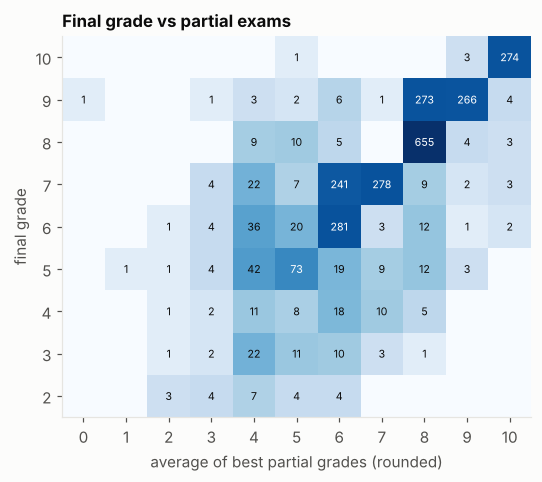

In [9]:
w = ex.pivot_table(index=["user_uuid", "course_uuid"], columns="exam_code", values="grade")
w = w.join(model_enr.set_index(["user_uuid", "course_uuid"])["final_grade"])
w["best_partials_avg"] = pd.concat(
    [w[["P1", "R1"]].max(axis=1), w[["P2", "R2"]].max(axis=1)], axis=1
).mean(axis=1)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
tab = pd.crosstab(w["final_grade"], w["best_partials_avg"].round()).sort_index(ascending=False)
im = ax.imshow(np.log1p(tab.values), cmap="Blues", aspect="auto")
ax.set_xticks(range(tab.shape[1]), [f"{c:.0f}" for c in tab.columns])
ax.set_yticks(range(tab.shape[0]), [f"{r:.0f}" for r in tab.index])
ax.set_xlabel("average of best partial grades (rounded)")
ax.set_ylabel("final grade")
ax.set_title("Final grade vs partial exams")
ax.grid(False)
for i in range(tab.shape[0]):
    for j in range(tab.shape[1]):
        v = tab.values[i, j]
        if v:
            ax.text(
                j,
                i,
                v,
                ha="center",
                va="center",
                fontsize=7,
                color="white" if np.log1p(v) > np.log1p(tab.values.max()) * 0.6 else "#0b0b0b",
            )
save(fig, "01_final_vs_partials")
same = (w["final_grade"] == w["best_partials_avg"].round()).mean()
print(
    f"final grade == rounded average of best partials in {same:.0%} of enrollments; "
    f"Spearman rho = {w[['final_grade', 'best_partials_avg']].corr('spearman').iloc[0, 1]:.2f}"
)

The final grade is **largely determined by the partial exams** (ρ ≈ 0.9). A model fed with every exam therefore looks excellent but is close to re-implementing the grading rule. The useful question is how early the risk can be detected, which is how the modeling is framed.

## 6. Engagement over the course: passed vs failed

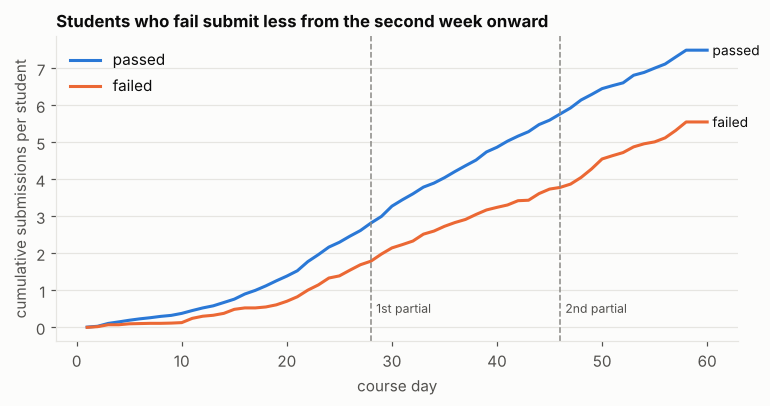

In [10]:
subs = t.submissions.merge(model_enr[["user_uuid", "course_uuid", "passed"]])
n_by_outcome = model_enr.groupby("passed").size()
daily = (
    subs.groupby(["passed", "particion"]).size().unstack(0).reindex(range(60)).fillna(0).cumsum()
    / n_by_outcome
)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(daily.index + 1, daily[1], color=PASS, label="passed")
ax.plot(daily.index + 1, daily[0], color=FAIL, label="failed")
ax.set_xlabel("course day")
ax.set_ylabel("cumulative submissions per student")
ax.set_title("Students who fail submit less from the second week onward")
for x, lab in [(28, "1st partial"), (46, "2nd partial")]:
    ax.axvline(x, color=NEUTRAL, lw=1, ls="--")
    ax.text(x + 0.5, ax.get_ylim()[1] * 0.05, lab, color="#52514e", fontsize=8)
ax.text(60.5, daily[1].iloc[-1], "passed", color="#0b0b0b", va="center", fontsize=9)
ax.text(60.5, daily[0].iloc[-1], "failed", color="#0b0b0b", va="center", fontsize=9)
ax.legend(loc="upper left")
save(fig, "01_engagement_curves")

,count,mean,std,min,25%,50%,75%,max
passed,,,,,,,,
0,151.0,77.3,15.6,0.0,67.7,79.0,88.0,100.0
1,2787.0,85.4,9.2,0.0,80.5,86.7,91.9,100.0


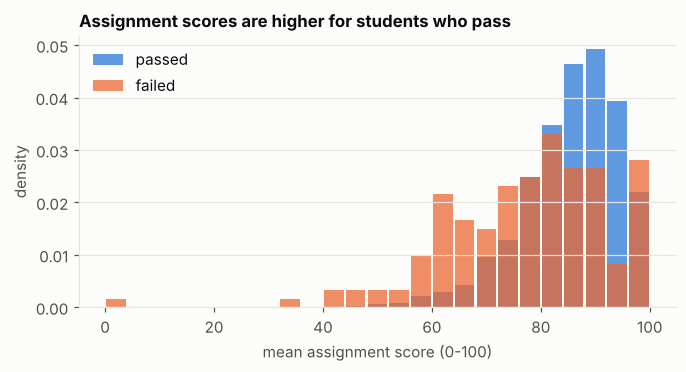

In [11]:
by = subs.groupby(["user_uuid", "course_uuid", "passed"])["score"].mean().reset_index()
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.linspace(0, 100, 26)
ax.hist(
    by.loc[by.passed == 1, "score"],
    bins=bins,
    density=True,
    color=PASS,
    alpha=0.75,
    label="passed",
    rwidth=0.9,
)
ax.hist(
    by.loc[by.passed == 0, "score"],
    bins=bins,
    density=True,
    color=FAIL,
    alpha=0.75,
    label="failed",
    rwidth=0.9,
)
ax.set_xlabel("mean assignment score (0-100)")
ax.set_ylabel("density")
ax.set_title("Assignment scores are higher for students who pass")
ax.legend(loc="upper left")
save(fig, "01_scores_by_outcome")
by.groupby("passed")["score"].describe().round(1)

In [12]:
mix = (
    subs.assign(type=subs["submission_type"].replace({"basic_lti_launch": "external_tool"}))
    .groupby(["passed", "type"])
    .size()
    .unstack(0)
    .fillna(0)
)
mix = (mix / mix.sum()).mul(100).round(1).sort_values(1, ascending=False)
mix.columns = ["failed %", "passed %"]
mix

,failed %,passed %
type,,
external_tool,53.3,48.8
online_quiz,31.9,37.5
online_upload,14.5,13.4
discussion_topic,0.1,0.2
online_text_entry,0.1,0.1
media_recording,0.0,0.0


## 7. Takeaways for feature engineering

| Observation | Feature(s) derived |
|---|---|
| Exams arrive on fixed days and dominate the final grade | per-exam grades, best of partial/make-up, `took_R1/R2`, `any_exam_below_pass`, computed **only from exams before the cutoff** |
| Assignment quality *and* volume both separate outcomes (failing students submit ~25% less and score ~8 points lower) | mean / min / std / last score, share of low scores |
| Volume and regularity still add context | submissions, assignments seen, submission rate, active days, recency, recent activity |
| Lock date = due date, so lateness is impossible | submission margin (median hours before due, share in the last 24h) instead of "late" flags |
| Students take several courses in parallel | `n_courses_in_period` (workload), `course_size` |

Feature definitions live in `src/early_warning/features/build.py`; their statistical relevance is tested in notebook 02.